# DS-A4: Model Comparison, Calibration, and Capacity-Constrained Review

## Scope and research question

This notebook executes the frozen Phase 2 protocol for the UCI Default of Credit Card Clients dataset. It asks whether Logistic Regression, Random Forest, and HistGradientBoosting differ in next-month-default discrimination and probability quality, and how their calibrated scores behave under hypothetical review costs and capacity limits.

This is a historical, offline predictive study. A next-month default label does not show that human review or intervention prevents default. The cost units and review capacity are assumptions, not measured monetary or operational quantities. Results do not establish present-day borrower performance or deployment suitability.

## Why this dataset and these models

The dataset contains 30,000 historical customer records with repayment, bill, and payment histories plus demographic fields. The 19-feature primary allowlist uses financial and repayment history; ID, target, and demographics are excluded from model inputs. Logistic Regression is a transparent simple baseline. Random Forest and histogram gradient boosting represent two nonlinear tree-based approaches. All use the same fold assignments, feature information, preprocessing pipeline, and average-precision selection metric.

## Why frozen paired evaluation and calibration

Every configuration is evaluated on the same five saved CV folds. The final test set is held until model selection, independent sigmoid calibration, and threshold decisions are locked. Paired bootstrap resamples use shared test-row indices for all models, enabling paired differences. Calibration tests probability agreement; it is distinct from ranking and may improve or worsen Brier score or ECE.

## Reproducibility gate

The protocol SHA-256 and split artifact SHA-256 are checked before any fit. Set `RUN_FULL_EXPERIMENT = True` in the execution cell to replay all 180 frozen CV fits, refits, calibration, decisions, and test evaluation. The default is `False` so a clean-kernel review can validate and render the already-computed, hash-verified Phase 2 artifacts without repeating the expensive model search. Model and threshold results are produced from the frozen protocol, not written in advance.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "experiment.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.experiment import run_experiment
from scripts.finalize_reports import finalize_reports

RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    run_manifest = run_experiment()
else:
    run_manifest = finalize_reports()
print(json.dumps(run_manifest, indent=2))

{
  "status": "Phase 2 core experiment and reports complete; independent review pending",
  "protocol_sha256": "03ffa36a02fcdbbf8df8484ffdb84f58e063819899409812cb4e46a87abae418",
  "split_sha256": "ded744149bd5afead62f3355d773eded3e9be1c8a53a5deabee38e104f42b1ed",
  "source_sha256": "56c885f84457f6680f8438f02bfcdac9579323d8a94465ee5f26e32baa727602",
  "cv_fit_seconds_by_model": {
    "HistGradientBoosting": 170.86625708360225,
    "Logistic Regression": 8.99953621032182,
    "Random Forest": 975.4749579175841
  },
  "cv_fit_seconds_total": 1155.3407512115082,
  "cv_config_fold_fits": 180,
  "cv_failures": 0,
  "convergence_warning_count": 0,
  "bootstrap_replicates": 2000,
  "bootstrap_seed": 2026,
  "one_class_bootstrap_resamples": 0,
  "python": "3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:46:00) [Clang 18.1.8 ]",
  "pandas": "2.3.1",
  "numpy": "2.2.6",
  "scikit_learn": "1.7.1",
  "wall_seconds_for_report_finalization": 2.2268617920344695,
  "model_training_performed

## Frozen CV selection

The primary selection metric is mean five-fold non-interpolated average precision. Configuration-level fold results, warnings, failures, and fit times are preserved under `results/cv/`. Equal configuration counts do not imply equal CPU time.

In [2]:
cv_summary = pd.read_csv(PROJECT_ROOT / "results/cv/cv_fold_results.csv")
selected = json.loads((PROJECT_ROOT / "results/cv/selected_models.json").read_text())
selected_table = pd.DataFrame([
    {"model": model, **record["params"], "selected_config": record["config_index"],
     "mean_cv_AP": record["mean_cv_ap"], "sd_cv_AP": record["std_cv_ap"]}
    for model, record in selected.items()
])
display(selected_table)
print("Fold/configuration rows:", len(cv_summary), "; failed folds:", int((cv_summary.status == "failed").sum()))
print("Convergence-warning records:", int(cv_summary.convergence_warning_count.sum()))

,model,C,class_weight,selected_config,mean_cv_AP,sd_cv_AP,max_depth,min_samples_leaf,max_features,learning_rate,max_leaf_nodes,l2_regularization
0,Logistic Regression,3.0,NaN,11,0.542502,0.010896,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,NaN,NaN,4,0.556518,0.017410,8.0,5.0,0.7,NaN,NaN,NaN
2,HistGradientBoosting,NaN,NaN,1,0.560583,0.013669,NaN,NaN,NaN,0.03,15.0,0.0


Fold/configuration rows: 180 ; failed folds: 0
Convergence-warning records: 0


## Final Test discrimination and probability quality

Raw and sigmoid-calibrated probabilities are reported separately. AP and ROC-AUC measure ranking; Brier score and ECE summarize probability quality. ECE uses the frozen ten equal-width bins, whose counts and observed rates are available in `results/calibration/final_test_reliability_bins.csv`. None of these test results are used to revise models, calibration, or thresholds.

In [3]:
test_metrics = pd.read_csv(PROJECT_ROOT / "results/statistics/final_test_metrics.csv")
bootstrap = pd.read_csv(PROJECT_ROOT / "results/statistics/bootstrap_intervals.csv")
ap_intervals = bootstrap[bootstrap.metric == "average_precision"][["model", "probability_type", "ci_95_low", "ci_95_high"]]
metric_view = test_metrics[test_metrics.probability_type.isin(["raw", "sigmoid"])].merge(
    ap_intervals, on=["model", "probability_type"], how="left")
display(metric_view[["model", "probability_type", "average_precision", "ci_95_low", "ci_95_high",
                     "roc_auc", "brier_score", "ece"]])
valid_ap = bootstrap.loc[bootstrap.metric == "average_precision", "valid_replicates"].min()
print("Valid paired bootstrap replicates for ranking metrics:", int(valid_ap), "of", run_manifest["bootstrap_replicates"])
print("One-class resamples rejected for AP/ROC-AUC:", run_manifest["one_class_bootstrap_resamples"])

,model,probability_type,average_precision,ci_95_low,ci_95_high,roc_auc,brier_score,ece
0,Logistic Regression,raw,0.557409,0.524583,0.589434,0.769384,0.135277,0.013701
1,Logistic Regression,sigmoid,0.557409,0.524583,0.589434,0.769384,0.135534,0.015378
2,Random Forest,raw,0.575000,0.542992,0.605773,0.782006,0.132742,0.013153
3,Random Forest,sigmoid,0.575000,0.542992,0.605773,0.782006,0.133677,0.017846
4,HistGradientBoosting,raw,0.579842,0.546047,0.611518,0.788150,0.131997,0.011130
5,HistGradientBoosting,sigmoid,0.579842,0.546047,0.611518,0.788150,0.131919,0.010603


Valid paired bootstrap replicates for ranking metrics: 2000 of 2000
One-class resamples rejected for AP/ROC-AUC: 0


## Calibration diagnostics

Reliability diagrams show mean predicted probability against observed positive frequency. A curve closer to the diagonal is better calibrated for these data and bins, but binning is noisy and does not establish calibration under population shift.

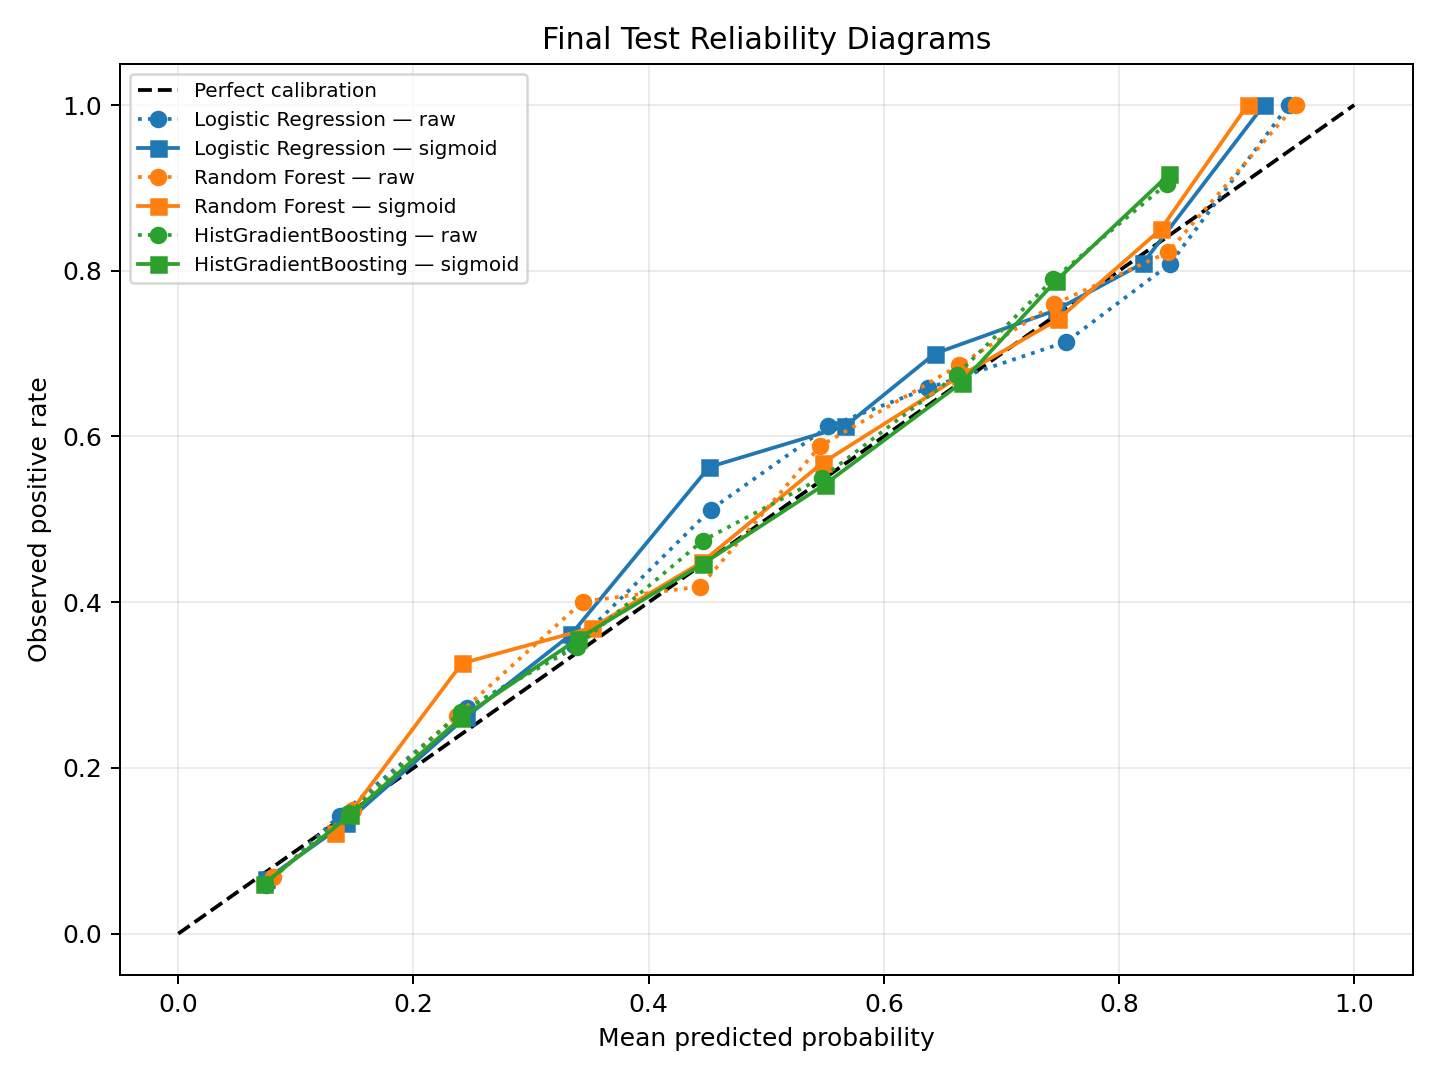

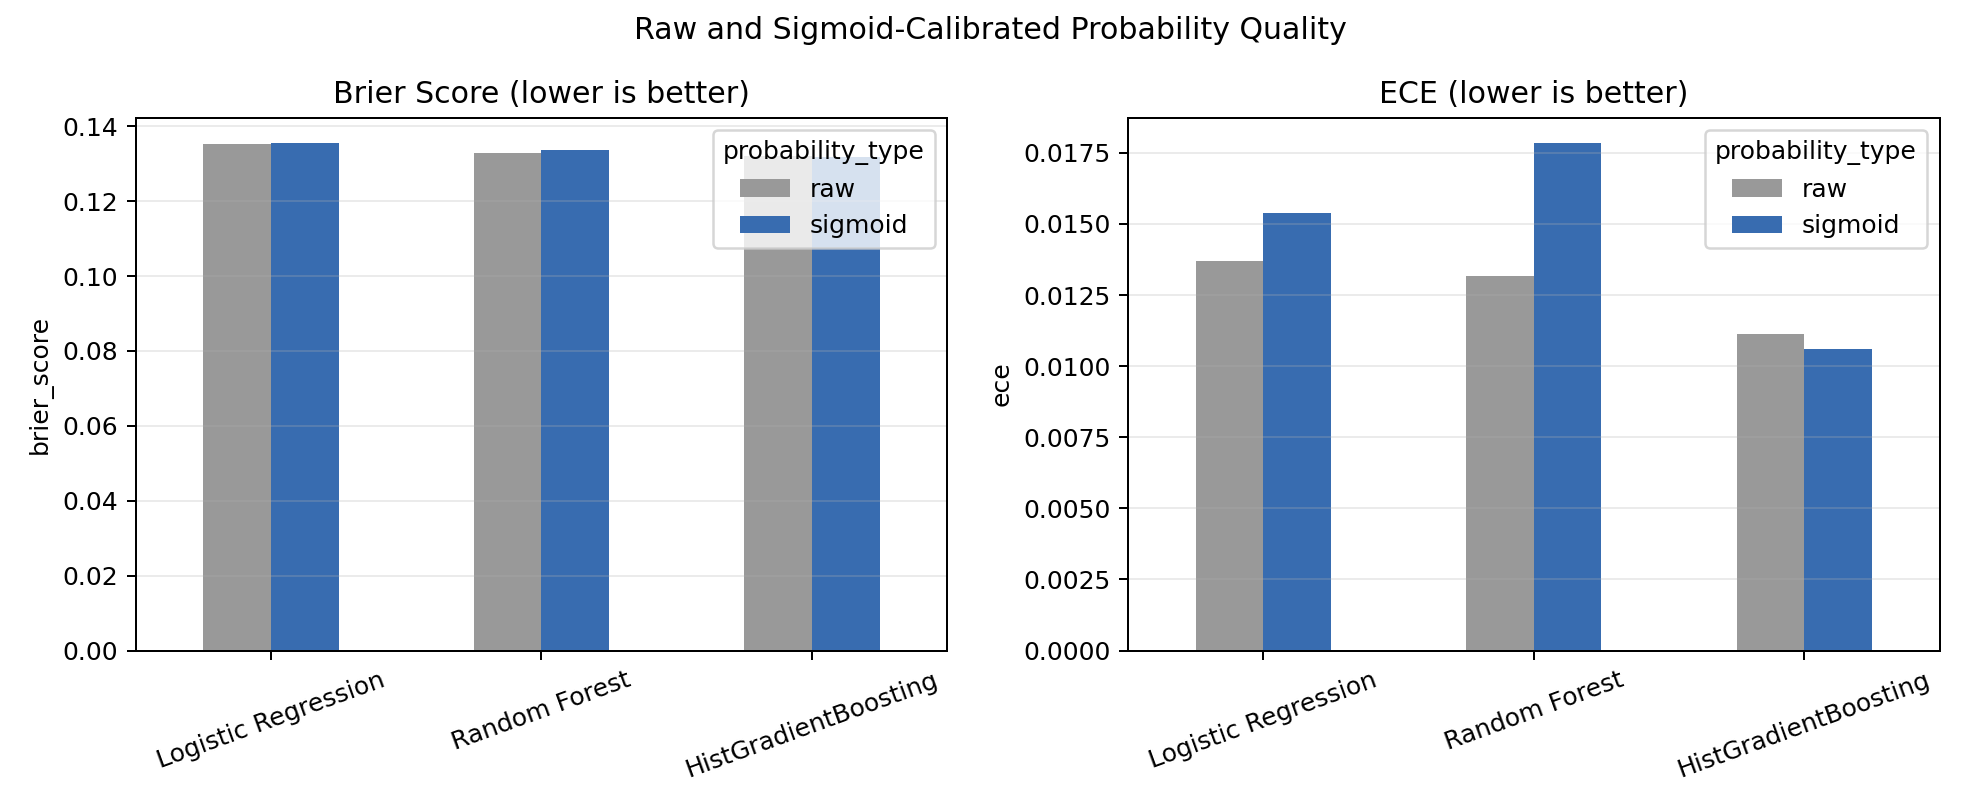

,model,probability_type,bin,lower,upper,count,mean_probability,observed_positive_rate
0,Logistic Regression,raw,0,0.0,0.1,685,0.074659,0.058394
1,Logistic Regression,raw,1,0.1,0.2,2609,0.137087,0.142583
2,Logistic Regression,raw,2,0.2,0.3,390,0.245436,0.271795
3,Logistic Regression,raw,3,0.3,0.4,218,0.336495,0.348624
4,Logistic Regression,raw,4,0.4,0.5,86,0.452657,0.511628
5,Logistic Regression,raw,5,0.5,0.6,98,0.552854,0.612245
6,Logistic Regression,raw,6,0.6,0.7,196,0.637150,0.658163
7,Logistic Regression,raw,7,0.7,0.8,91,0.755252,0.714286
8,Logistic Regression,raw,8,0.8,0.9,125,0.843196,0.808000
9,Logistic Regression,raw,9,0.9,1.0,2,0.944296,1.000000


In [4]:
display(Image(filename=str(PROJECT_ROOT / "results/figures/reliability_diagrams.png")))
display(Image(filename=str(PROJECT_ROOT / "results/figures/calibration_comparison.png")))
reliability = pd.read_csv(PROJECT_ROOT / "results/calibration/final_test_reliability_bins.csv")
display(reliability.head(20))

## Paired uncertainty

The bootstrap intervals condition on the three fitted models and the frozen test sample. They do not account for hyperparameter selection, retraining variability, temporal shift, or future deployment uncertainty. Paired differences are model minus Logistic Regression; negative differences favor the compared model for Brier/ECE, while positive differences favor it for AP/ROC-AUC.

In [5]:
display(bootstrap[["model", "probability_type", "metric", "test_estimate", "ci_95_low", "ci_95_high",
                  "valid_replicates", "paired_difference_vs_logistic",
                  "paired_difference_ci_95_low", "paired_difference_ci_95_high"]])

,model,probability_type,metric,test_estimate,ci_95_low,ci_95_high,valid_replicates,paired_difference_vs_logistic,paired_difference_ci_95_low,paired_difference_ci_95_high
0,Logistic Regression,raw,average_precision,0.557409,0.524583,0.589434,2000,0.000000,0.000000,0.000000
1,Random Forest,raw,average_precision,0.575000,0.542992,0.605773,2000,0.017591,0.002713,0.031650
2,HistGradientBoosting,raw,average_precision,0.579842,0.546047,0.611518,2000,0.022433,0.010775,0.034414
3,Logistic Regression,raw,roc_auc,0.769384,0.752055,0.786855,2000,0.000000,0.000000,0.000000
4,Random Forest,raw,roc_auc,0.782006,0.764596,0.798740,2000,0.012622,0.002008,0.022216
5,HistGradientBoosting,raw,roc_auc,0.788150,0.771248,0.804729,2000,0.018766,0.009340,0.028088
6,Logistic Regression,raw,brier_score,0.135277,0.128822,0.142041,2000,0.000000,0.000000,0.000000
7,Random Forest,raw,brier_score,0.132742,0.126364,0.139210,2000,-0.002535,-0.004143,-0.000943
8,HistGradientBoosting,raw,brier_score,0.131997,0.125696,0.138314,2000,-0.003280,-0.004699,-0.001843
9,Logistic Regression,raw,ece,0.013701,0.009342,0.025898,2000,0.000000,0.000000,0.000000


## Threshold decisions and sensitivity

Thresholds are selected on the separate Threshold Selection subset using calibrated probabilities, then applied unchanged to Final Test. A test flagged fraction above 10% is reported as observed and is not corrected. Top-K is a separate hard-capacity policy with an explicit row-index tie break; it is not a probability-threshold rule.

,model,threshold,flagged_n_selection,flagged_fraction_selection,hypothetical_loss_selection,maximum_flags,flagged_n_test,flagged_fraction_test,hypothetical_loss_test
0,Logistic Regression,0.567186,298,0.099333,2424.0,300,416.0,0.092444,3603.0
1,Random Forest,0.571389,300,0.100000,2408.0,300,425.0,0.094444,3528.0
2,HistGradientBoosting,0.591527,300,0.100000,2414.0,300,420.0,0.093333,3541.0


,model,capacity,fn_to_fp_ratio,threshold,flagged_fraction,hypothetical_loss,test_flagged_fraction,test_hypothetical_loss
0,Logistic Regression,0.05,2.0,0.694327,0.049000,1157.0,0.044222,1730.0
1,Logistic Regression,0.05,5.0,0.691173,0.050000,2828.0,0.045111,4242.0
2,Logistic Regression,0.05,10.0,0.691173,0.050000,5613.0,0.045111,8437.0
3,Logistic Regression,0.10,2.0,0.567186,0.099333,1029.0,0.092444,1512.0
4,Logistic Regression,0.10,5.0,0.567186,0.099333,2424.0,0.092444,3603.0
5,Logistic Regression,0.10,10.0,0.567186,0.099333,4749.0,0.092444,7088.0
6,Logistic Regression,0.20,2.0,0.308830,0.181000,923.0,0.171111,1365.0
7,Logistic Regression,0.20,5.0,0.292244,0.197000,1931.0,0.184444,2919.0
8,Logistic Regression,0.20,10.0,0.292244,0.197000,3601.0,0.184444,5489.0
9,Random Forest,0.05,2.0,0.742839,0.049000,1151.0,0.042889,1712.0


,model,capacity,k,boundary_probability,records_tied_at_boundary,test_k,test_flagged_fraction,test_hypothetical_loss
0,Logistic Regression,0.05,150,0.691173,1,225,0.05,4156.0
1,Logistic Regression,0.10,300,0.563527,1,450,0.10,3535.0
2,Logistic Regression,0.20,600,0.288078,4,900,0.20,2863.0
3,Random Forest,0.05,150,0.742393,1,225,0.05,4120.0
4,Random Forest,0.10,300,0.571389,1,450,0.10,3463.0
5,Random Forest,0.20,600,0.271288,6,900,0.20,2767.0
6,HistGradientBoosting,0.05,150,0.708355,1,225,0.05,4120.0
7,HistGradientBoosting,0.10,300,0.591527,1,450,0.10,3469.0
8,HistGradientBoosting,0.20,600,0.313945,24,900,0.20,2821.0


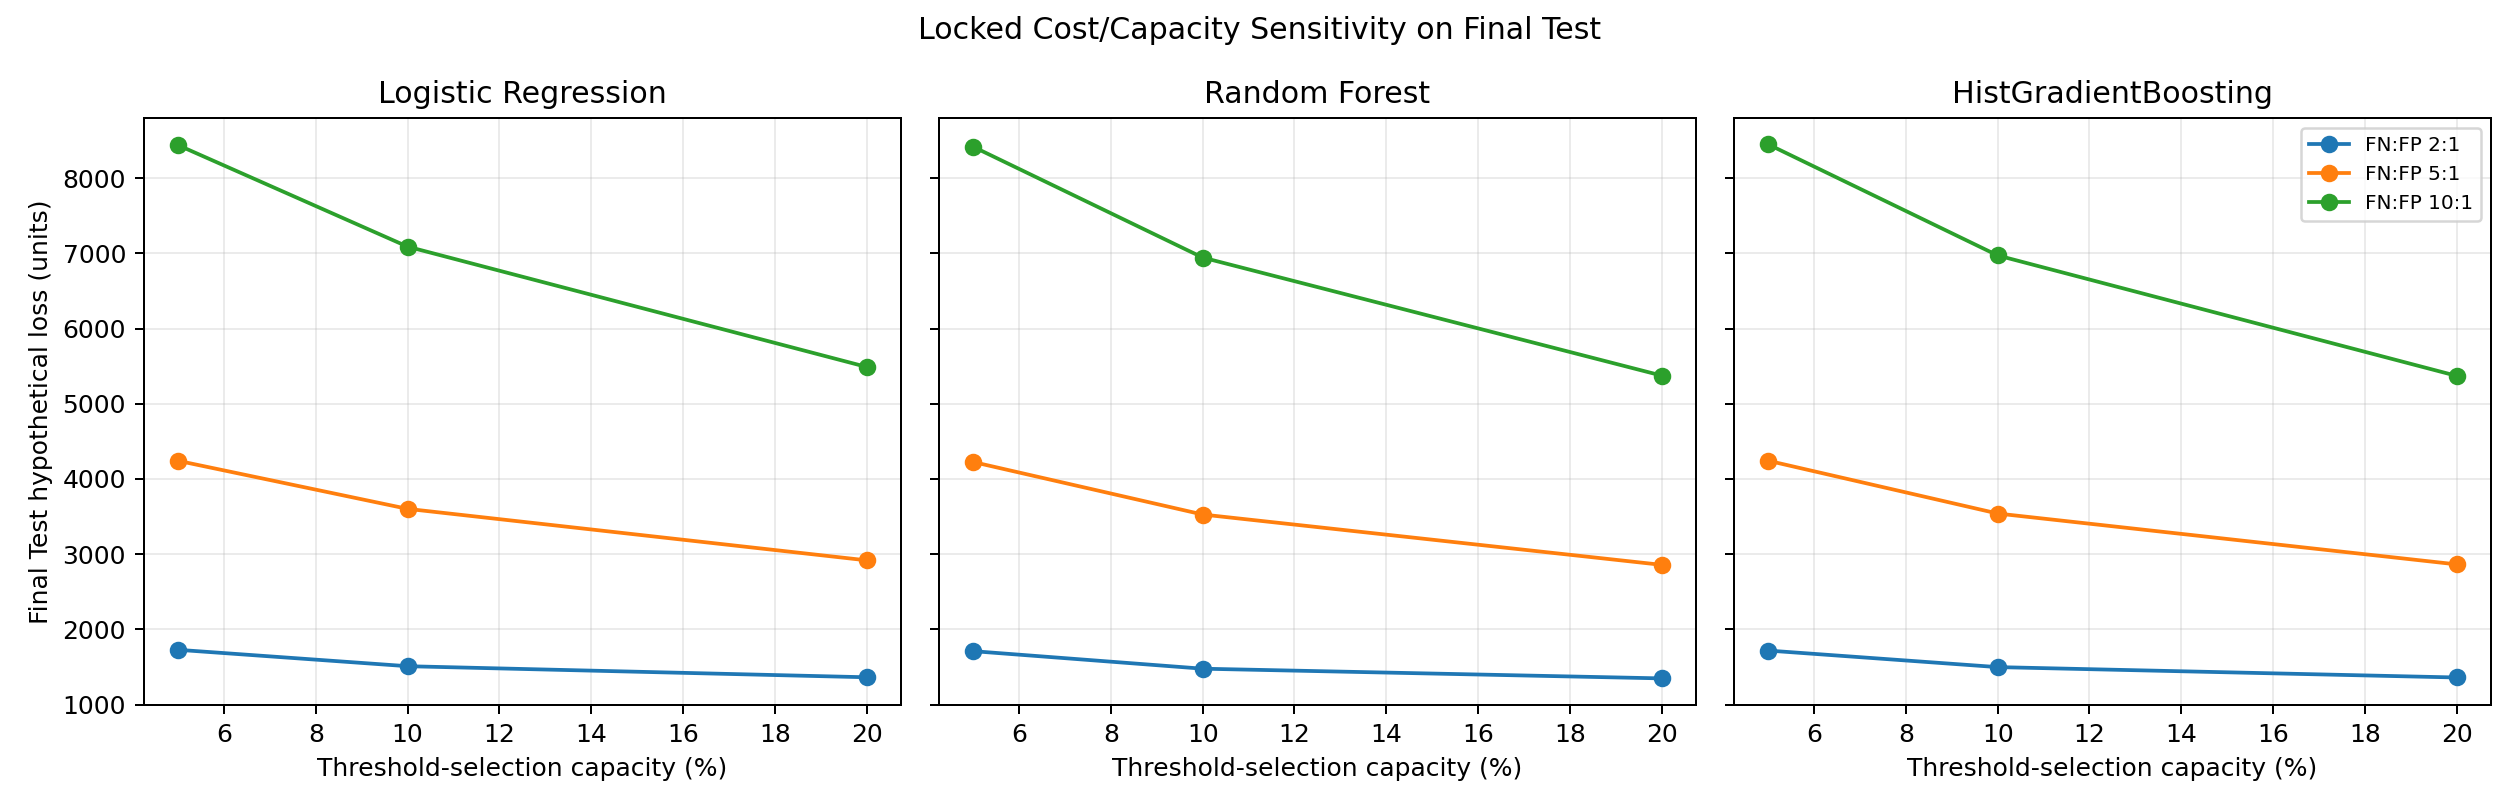

In [6]:
decision = json.loads((PROJECT_ROOT / "results/decisions/locked_decisions.json").read_text())
threshold_test = test_metrics[test_metrics.probability_type == "locked_threshold_test"]
sensitivity = pd.read_csv(PROJECT_ROOT / "results/decisions/cost_capacity_sensitivity.csv")
top_k = pd.read_csv(PROJECT_ROOT / "results/decisions/top_k_test_results.csv")
display(pd.DataFrame([{"model": m, **{k: v for k, v in d.items() if k in ["threshold", "flagged_n", "flagged_fraction", "hypothetical_loss", "maximum_flags"]}}
                      for m, d in decision["primary"].items()]).merge(
    threshold_test[["model", "flagged_n", "flagged_fraction", "hypothetical_loss"]], on="model", suffixes=("_selection", "_test")))
display(sensitivity[["model", "capacity", "fn_to_fp_ratio", "threshold", "flagged_fraction", "hypothetical_loss", "test_flagged_fraction", "test_hypothetical_loss"]])
display(top_k[["model", "capacity", "k", "boundary_probability", "records_tied_at_boundary", "test_k", "test_flagged_fraction", "test_hypothetical_loss"]])
display(Image(filename=str(PROJECT_ROOT / "results/figures/cost_capacity_sensitivity.png")))

## Slices, error types, and duplicate-profile diagnostic

Behavioral slices are defined from repayment codes and Train+CV-only cutpoints. Demographic fields appear only in a supplementary aggregate error audit. Sparse groups are shown with their support and should not be interpreted as stable estimates. Exact matching of the 19 observable features is not evidence that two records belong to the same individual.

,slice,group,model,n,positive,negative,average_precision,roc_auc,brier_score,ece,threshold_fp,threshold_fn
0,PAY_0 grouped,-1,Logistic Regression,878,142,736,0.273890,0.671277,0.129689,0.019688,0,142
1,PAY_0 grouped,-1,Random Forest,878,142,736,0.317585,0.694250,0.127090,0.011797,1,142
2,PAY_0 grouped,-1,HistGradientBoosting,878,142,736,0.317849,0.701173,0.125612,0.014207,0,141
3,PAY_0 grouped,-2,Logistic Regression,419,59,360,0.148418,0.542491,0.121699,0.017484,0,59
4,PAY_0 grouped,-2,Random Forest,419,59,360,0.272212,0.683828,0.117045,0.044075,0,59
5,PAY_0 grouped,-2,HistGradientBoosting,419,59,360,0.287015,0.694374,0.114415,0.033338,0,59
6,PAY_0 grouped,0,Logistic Regression,2229,285,1944,0.243093,0.654397,0.107719,0.015160,0,285
7,PAY_0 grouped,0,Random Forest,2229,285,1944,0.242761,0.662160,0.107293,0.018305,0,284
8,PAY_0 grouped,0,HistGradientBoosting,2229,285,1944,0.249125,0.678925,0.105846,0.012041,0,285
9,PAY_0 grouped,>=1,Logistic Regression,974,509,465,0.734637,0.731445,0.210410,0.037507,118,211


,field,group,model,n,positive,negative,tp,fp,tn,fn
0,SEX,1,Logistic Regression,1779,421,1358,118,40,1318,303
1,SEX,1,Random Forest,1779,421,1358,128,36,1322,293
2,SEX,1,HistGradientBoosting,1779,421,1358,129,38,1320,292
3,SEX,2,Logistic Regression,2721,574,2147,180,78,2069,394
4,SEX,2,Random Forest,2721,574,2147,184,77,2070,390
5,SEX,2,HistGradientBoosting,2721,574,2147,180,73,2074,394
6,EDUCATION,1,Logistic Regression,1628,329,1299,87,25,1274,242
7,EDUCATION,1,Random Forest,1628,329,1299,98,27,1272,231
8,EDUCATION,1,HistGradientBoosting,1628,329,1299,98,27,1272,231
9,EDUCATION,2,Logistic Regression,2024,465,1559,150,54,1505,315


{
  "calibration": {
    "n": 4500,
    "overlap_n": 128,
    "overlap_fraction": 0.028444444444444446,
    "nonoverlap_n": 4372
  },
  "threshold_selection": {
    "n": 3000,
    "overlap_n": 101,
    "overlap_fraction": 0.033666666666666664,
    "nonoverlap_n": 2899
  },
  "final_test": {
    "n": 4500,
    "overlap_n": 127,
    "overlap_fraction": 0.02822222222222222,
    "nonoverlap_n": 4373
  }
}


,profile_group,model,n,positive,negative,average_precision,roc_auc,brier_score,ece,threshold_tp,...,threshold_fn,threshold_precision,threshold_precision_undefined_reason,threshold_recall,threshold_recall_undefined_reason,threshold_false_positive_rate,threshold_fpr_undefined_reason,threshold_flagged_n,threshold_flagged_fraction,threshold_hypothetical_loss
0,overlap,Logistic Regression,127,57,70,0.509839,0.482080,0.285120,0.195461,5,...,52,1.000000,NaN,0.087719,NaN,0.000000,NaN,5,0.039370,260.0
1,overlap,Random Forest,127,57,70,0.579443,0.579198,0.269878,0.184850,5,...,52,1.000000,NaN,0.087719,NaN,0.000000,NaN,5,0.039370,260.0
2,overlap,HistGradientBoosting,127,57,70,0.576272,0.591604,0.254950,0.148346,5,...,52,1.000000,NaN,0.087719,NaN,0.000000,NaN,5,0.039370,260.0
3,nonoverlap,Logistic Regression,4373,938,3435,0.557118,0.773655,0.131190,0.017743,293,...,645,0.712895,NaN,0.312367,NaN,0.034352,NaN,411,0.093986,3343.0
4,nonoverlap,Random Forest,4373,938,3435,0.570619,0.780652,0.129722,0.014709,307,...,631,0.730952,NaN,0.327292,NaN,0.032897,NaN,420,0.096044,3268.0
5,nonoverlap,HistGradientBoosting,4373,938,3435,0.576689,0.787359,0.128346,0.008002,304,...,634,0.732530,NaN,0.324094,NaN,0.032314,NaN,415,0.094901,3281.0


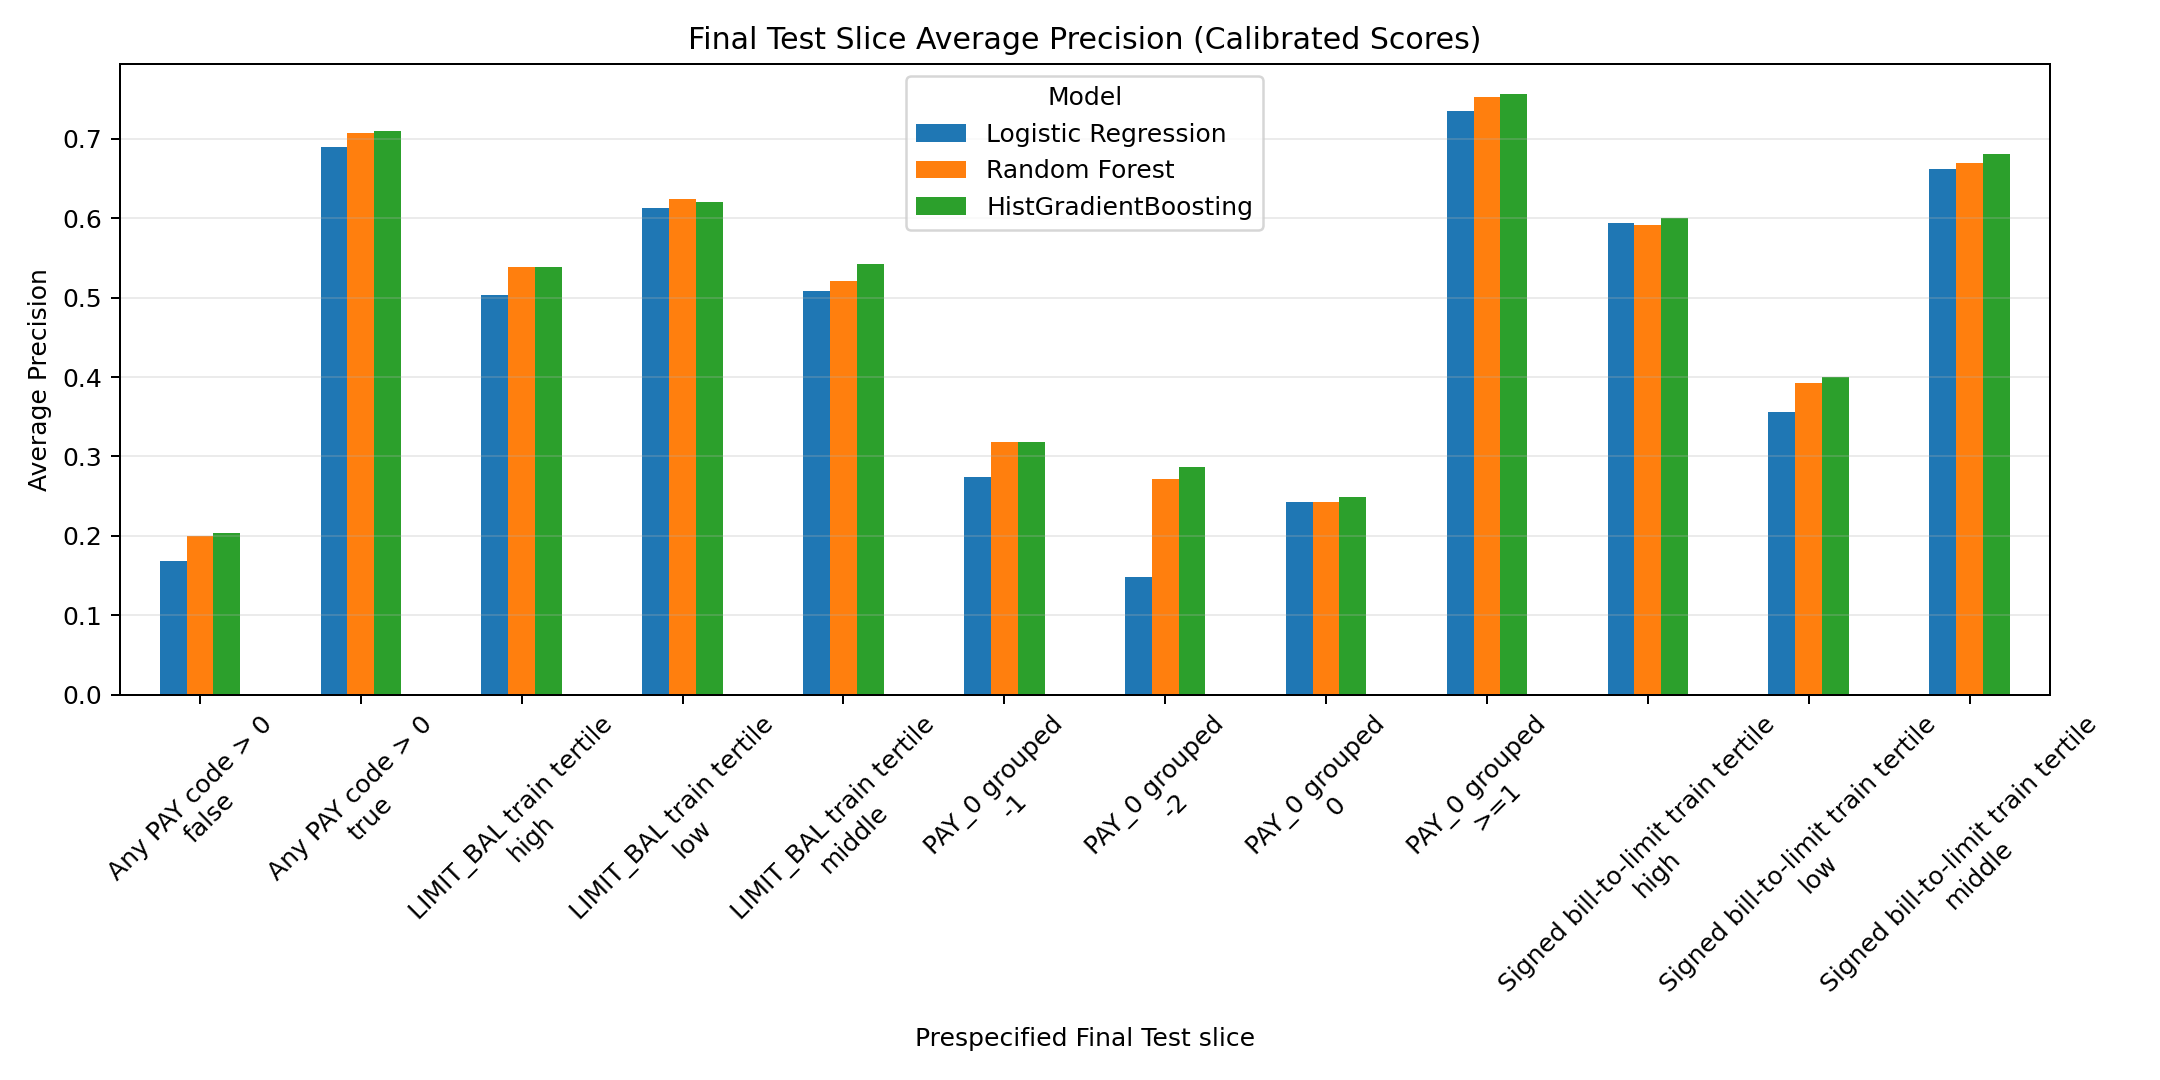

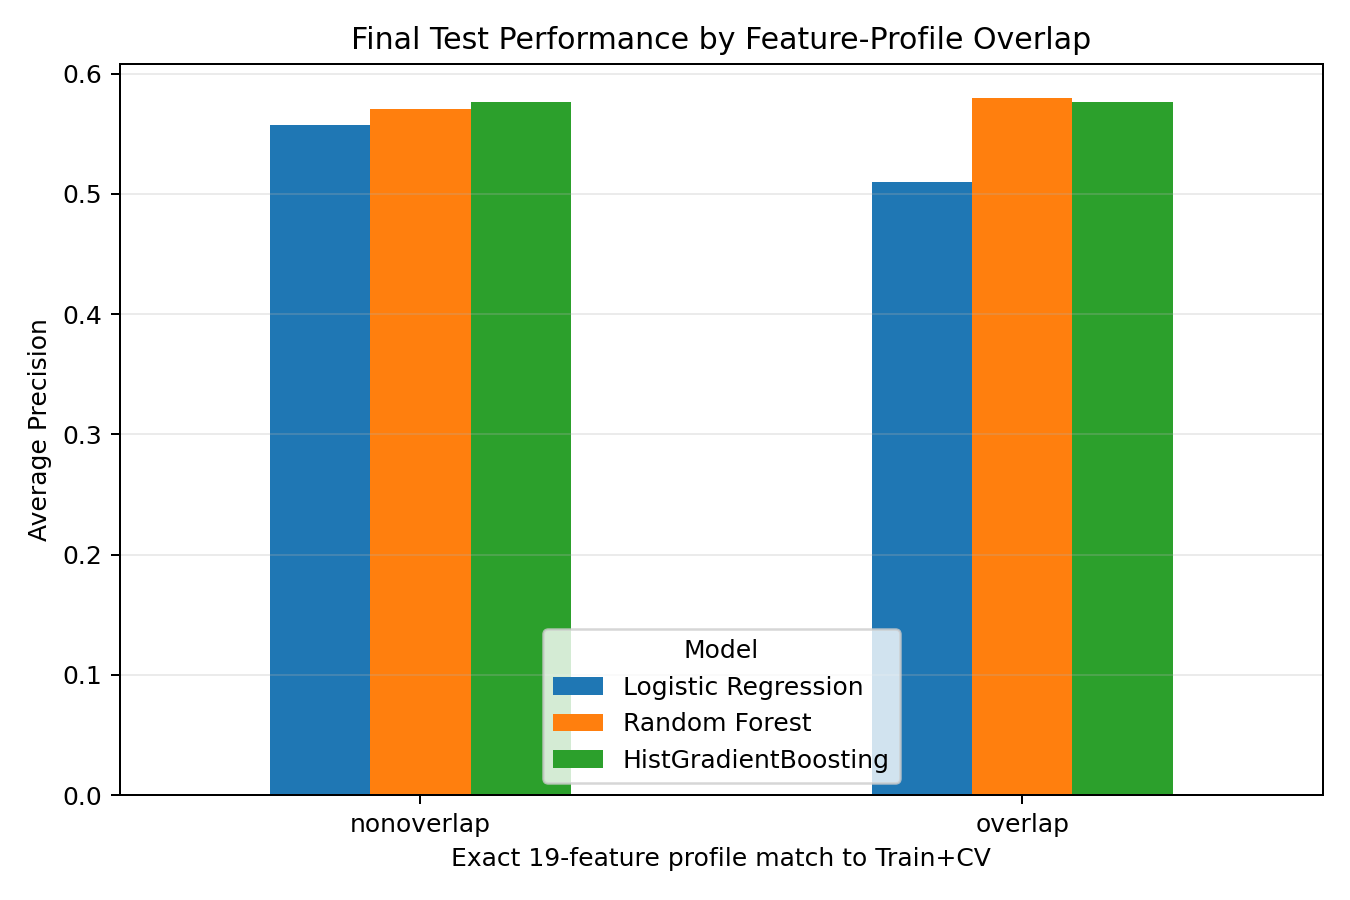

In [7]:
slices = pd.read_csv(PROJECT_ROOT / "results/slices/final_test_behavioral_slices.csv")
demographic_errors = pd.read_csv(PROJECT_ROOT / "results/slices/supplementary_demographic_error_audit.csv")
overlap = json.loads((PROJECT_ROOT / "results/diagnostics/duplicate_profile_overlap.json").read_text())
overlap_metrics = pd.read_csv(PROJECT_ROOT / "results/diagnostics/test_overlap_group_metrics.csv")
display(slices[["slice", "group", "model", "n", "positive", "negative", "average_precision", "roc_auc", "brier_score", "ece", "threshold_fp", "threshold_fn"]])
display(demographic_errors.head(24))
print(json.dumps(overlap, indent=2))
display(overlap_metrics)
display(Image(filename=str(PROJECT_ROOT / "results/figures/slice_average_precision.png")))
display(Image(filename=str(PROJECT_ROOT / "results/figures/duplicate_profile_overlap.png")))

## Evidence-based interpretation and limitations

The next cell reports observed rankings and whether calibration changed each model's test Brier score or ECE. It does not assert that the numerically best model is universally superior. Read these results alongside paired intervals, slice support, threshold assumptions, and the duplicate-profile diagnostic. A lack of improvement or an unfavorable subgroup result is a valid finding.

In [8]:
raw = test_metrics[test_metrics.probability_type == "raw"].set_index("model")
cal = test_metrics[test_metrics.probability_type == "sigmoid"].set_index("model")
print("Observed raw AP ranking:", list(raw.average_precision.sort_values(ascending=False).index))
for model in raw.index:
    print(f"{model}: calibration delta Brier={cal.loc[model, 'brier_score']-raw.loc[model, 'brier_score']:+.6f}; "
          f"delta ECE={cal.loc[model, 'ece']-raw.loc[model, 'ece']:+.6f}")
print("These are conditional historical-sample results, not causal evidence of prevented default or a current-population guarantee.")

Observed raw AP ranking: ['HistGradientBoosting', 'Random Forest', 'Logistic Regression']
Logistic Regression: calibration delta Brier=+0.000258; delta ECE=+0.001676
Random Forest: calibration delta Brier=+0.000935; delta ECE=+0.004693
HistGradientBoosting: calibration delta Brier=-0.000078; delta ECE=-0.000528
These are conditional historical-sample results, not causal evidence of prevented default or a current-population guarantee.


## Artifact map

- `results/cv/`: all 180 planned CV fold/configuration records, selected parameters, and warnings.
- `results/models/`: Train+CV base estimators and independent sigmoid calibrators.
- `results/predictions/`: calibration, threshold-selection, and row-aligned one-pass Final Test predictions.
- `results/statistics/`: final metrics, paired bootstrap replicates/indices/intervals, and curve coordinates.
- `results/calibration/`: reliability-bin and calibration-subset evidence.
- `results/slices/`, `results/diagnostics/`, and `results/decisions/`: error slices, profile overlap, and locked threshold/capacity policies.
- `results/figures/`: publication-readable experiment figures.

This is Phase 2 core analysis only. The final PDF, submission summary, independent human review, repository commit/tag, and submission steps remain outside this phase.